#  **saas customer churn intelligience**

In [4]:
import pandas as pd
import matplotlib.pyplot as  plt
import seaborn as sns

In [5]:
mp_syn =r"C:\Users\hokto\Downloads\MP_Synthetics_50000_Rows.csv"

In [6]:
df = pd.read_csv(mp_syn)

In [7]:
df

,Customer_ID,Company_Name,Industry,Country,Company_Size,Account_Manager,Plan_Tier,Billing_Cycle,Monthly_Recurring_Revenue,Signup_Date,Last_Active_Date,Payment_Status,Active_Seats_Used,Total_Seats_Allowed,Support_Tickets_30d,Feature_Adoption_Rate,Churn_Risk_Score,Is_Churned
0,CUST-1001,Pulse Net 944,HealthTech,Australia,11-50,Sarah Jenkins,Starter,Annual,49,2025-03-12,2026-02-18,Active,3,8,5,44%,Low,0
1,CUST-1002,Pulse Logic 332,CyberSecurity,USA,51-200,David Ross,Pro,Annual,499,2023-09-29,2026-02-25,Active,13,24,3,58%,Low,0
2,CUST-1003,Secure Flow 975,DevTools,India,1-10,David Ross,Starter,Monthly,79,2025-03-16,2026-02-19,Active,6,8,5,70%,Low,0
3,CUST-1004,Quantum Scale 657,EdTech,Singapore,51-200,Marcus Vance,Pro,Annual,249,2024-03-05,2026-02-22,Active,34,39,2,90%,Low,0
4,CUST-1005,Quantum Sphere 308,E-Commerce,Germany,1-10,Aisha Khan,Starter,Monthly,129,2025-02-28,2026-02-22,Active,8,9,3,93%,Low,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,CUST-50996,Omni AI 147,CyberSecurity,Canada,1-10,Aisha Khan,Starter,Annual,129,2025-03-16,2026-02-17,Active,7,10,4,69%,Low,0
49996,CUST-50997,Vibe Logic 456,MarTech,India,1-10,Aisha Khan,Starter,Monthly,49,2024-11-16,2026-02-16,Active,7,8,3,88%,Low,0
49997,CUST-50998,Quantum Net 553,FinTech,UK,1-10,Sarah Jenkins,Starter,Monthly,49,2023-05-12,2026-02-19,Active,5,7,4,88%,Low,0
49998,CUST-50999,Pulse Flow 109,FinTech,France,1-10,David Ross,Starter,Monthly,49,2025-07-25,2026-02-20,Active,6,9,5,64%,Low,0


In [8]:
df.columns = df.columns.str.lower()
df.columns = df.columns.str.strip()

In [9]:
df["signup_date"] = pd.to_datetime(df["signup_date"],format ="%Y-%m-%d")
df["last_active_date"] = pd.to_datetime(df["last_active_date"],format ="%Y-%m-%d")

In [10]:
df["feature_adoption_rate"]

0        44%
1        58%
2        70%
3        90%
4        93%
        ... 
49995    69%
49996    88%
49997    88%
49998    64%
49999    69%
Name: feature_adoption_rate, Length: 50000, dtype: str

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df.shape

(50000, 18)

In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 18 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   customer_id                50000 non-null  str           
 1   company_name               50000 non-null  str           
 2   industry                   50000 non-null  str           
 3   country                    50000 non-null  str           
 4   company_size               50000 non-null  str           
 5   account_manager            50000 non-null  str           
 6   plan_tier                  50000 non-null  str           
 7   billing_cycle              50000 non-null  str           
 8   monthly_recurring_revenue  50000 non-null  int64         
 9   signup_date                50000 non-null  datetime64[us]
 10  last_active_date           50000 non-null  datetime64[us]
 11  payment_status             50000 non-null  str           
 12  active_seats_us

In [14]:
type(df)

pandas.DataFrame

In [15]:
df.isna().any()

customer_id                  False
company_name                 False
industry                     False
country                      False
company_size                 False
account_manager              False
plan_tier                    False
billing_cycle                False
monthly_recurring_revenue    False
signup_date                  False
last_active_date             False
payment_status               False
active_seats_used            False
total_seats_allowed          False
support_tickets_30d          False
feature_adoption_rate        False
churn_risk_score             False
is_churned                   False
dtype: bool

In [16]:
df.head(5)

,customer_id,company_name,industry,country,company_size,account_manager,plan_tier,billing_cycle,monthly_recurring_revenue,signup_date,last_active_date,payment_status,active_seats_used,total_seats_allowed,support_tickets_30d,feature_adoption_rate,churn_risk_score,is_churned
0,CUST-1001,Pulse Net 944,HealthTech,Australia,11-50,Sarah Jenkins,Starter,Annual,49,2025-03-12,2026-02-18,Active,3,8,5,44%,Low,0
1,CUST-1002,Pulse Logic 332,CyberSecurity,USA,51-200,David Ross,Pro,Annual,499,2023-09-29,2026-02-25,Active,13,24,3,58%,Low,0
2,CUST-1003,Secure Flow 975,DevTools,India,1-10,David Ross,Starter,Monthly,79,2025-03-16,2026-02-19,Active,6,8,5,70%,Low,0
3,CUST-1004,Quantum Scale 657,EdTech,Singapore,51-200,Marcus Vance,Pro,Annual,249,2024-03-05,2026-02-22,Active,34,39,2,90%,Low,0
4,CUST-1005,Quantum Sphere 308,E-Commerce,Germany,1-10,Aisha Khan,Starter,Monthly,129,2025-02-28,2026-02-22,Active,8,9,3,93%,Low,0


In [17]:
df.nunique()

customer_id                  50000
company_name                 38437
industry                         8
country                          8
company_size                     6
account_manager                  5
plan_tier                        3
billing_cycle                    2
monthly_recurring_revenue     3648
signup_date                   1170
last_active_date               164
payment_status                   3
active_seats_used              897
total_seats_allowed            897
support_tickets_30d              9
feature_adoption_rate           71
churn_risk_score                 3
is_churned                       2
dtype: int64

In [18]:
df["is_churned"].unique()

array([0, 1])

In [19]:
df["is_churned"].value_counts()

is_churned
0    49084
1      916
Name: count, dtype: int64

In [20]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
monthly_recurring_revenue,50000.0,665.35816,49.0,79.0,129.0,299.0,8499.0,1592.411168
signup_date,50000,2024-06-26 19:23:24.288000,2022-11-17 00:00:00,2023-09-10 00:00:00,2024-06-27 00:00:00,2025-04-16 00:00:00,2026-01-29 00:00:00,NaN
last_active_date,50000,2026-02-19 17:52:42.815999,2025-09-02 00:00:00,2026-02-18 00:00:00,2026-02-21 00:00:00,2026-02-25 00:00:00,2026-02-28 00:00:00,NaN
active_seats_used,50000.0,50.84396,1.0,3.0,6.0,26.0,976.0,133.757042
total_seats_allowed,50000.0,73.66436,3.0,6.0,9.0,39.0,999.0,185.526556
support_tickets_30d,50000.0,3.35136,0.0,2.0,3.0,5.0,8.0,1.681904
is_churned,50000.0,0.01832,0.0,0.0,0.0,0.0,1.0,0.134107


In [21]:
churned_data = df[df["is_churned"]==1]
print(churned_data)

      customer_id       company_name    industry    country company_size  \
116     CUST-1117   Quantum Tech 557      EdTech      India        11-50   
131     CUST-1132  Cloud Metrics 275     MarTech    Germany         1-10   
197     CUST-1198      Data Tech 683  E-Commerce        USA       51-200   
201     CUST-1202     Vibe Scale 531    DevTools  Australia      201-500   
211     CUST-1212     Nexus Labs 264     MarTech    Germany      201-500   
...           ...                ...         ...        ...          ...   
49505  CUST-50506  Nexus Metrics 457   Logistics     Canada         1-10   
49645  CUST-50646    Vibe Sphere 448     MarTech     France       51-200   
49737  CUST-50738     Pulse Flow 956    DevTools    Germany         1-10   
49779  CUST-50780       Vibe Net 599  HealthTech         UK         1-10   
49857  CUST-50858      Data Flow 932   Logistics    Germany         1-10   

      account_manager plan_tier billing_cycle  monthly_recurring_revenue  \
116        

In [22]:
churned_data["feature_adoption_rate"] =churned_data["feature_adoption_rate"].str.replace("%","", regex = False)
churned_data["feature_adoption_rate"] =churned_data["feature_adoption_rate"].astype(float)

In [23]:
churned_data["feature_adoption_rate"]

116      62.0
131      50.0
197      42.0
201      34.0
211      58.0
         ... 
49505    69.0
49645    38.0
49737    60.0
49779    36.0
49857    56.0
Name: feature_adoption_rate, Length: 916, dtype: float64

In [24]:
churned_data["is_churned"] =df["is_churned"].replace({1:"churned",0:"not_churned"})
print(churned_data)

      customer_id       company_name    industry    country company_size  \
116     CUST-1117   Quantum Tech 557      EdTech      India        11-50   
131     CUST-1132  Cloud Metrics 275     MarTech    Germany         1-10   
197     CUST-1198      Data Tech 683  E-Commerce        USA       51-200   
201     CUST-1202     Vibe Scale 531    DevTools  Australia      201-500   
211     CUST-1212     Nexus Labs 264     MarTech    Germany      201-500   
...           ...                ...         ...        ...          ...   
49505  CUST-50506  Nexus Metrics 457   Logistics     Canada         1-10   
49645  CUST-50646    Vibe Sphere 448     MarTech     France       51-200   
49737  CUST-50738     Pulse Flow 956    DevTools    Germany         1-10   
49779  CUST-50780       Vibe Net 599  HealthTech         UK         1-10   
49857  CUST-50858      Data Flow 932   Logistics    Germany         1-10   

      account_manager plan_tier billing_cycle  monthly_recurring_revenue  \
116        

In [25]:
churned_data.describe().T

,count,mean,min,25%,50%,75%,max,std
monthly_recurring_revenue,916.0,432.358079,49.0,79.0,99.0,249.0,8241.0,1249.103372
signup_date,916,2024-06-27 06:51:52.663755,2022-11-18 00:00:00,2023-10-01 00:00:00,2024-06-14 00:00:00,2025-04-29 06:00:00,2026-01-29 00:00:00,NaN
last_active_date,916,2025-11-16 07:24:53.449781,2025-09-02 00:00:00,2025-10-09 00:00:00,2025-11-19 00:00:00,2025-12-23 00:00:00,2026-01-29 00:00:00,NaN
active_seats_used,916.0,24.793668,1.0,2.0,3.0,9.0,731.0,80.563467
total_seats_allowed,916.0,46.507642,3.0,5.0,7.0,21.0,992.0,144.769774
support_tickets_30d,916.0,4.973799,0.0,4.0,5.0,6.0,8.0,1.432401
feature_adoption_rate,916.0,52.048035,31.0,42.0,50.0,59.0,100.0,13.431872


In [26]:
churned_data["company_name"].nunique()

911

In [27]:
industry_count =churned_data.groupby("industry").agg(industry_count = ("industry","count")).sort_values(by ="industry_count",ascending = False).head(5) .reset_index()
industry_count

,industry,industry_count
0,EdTech,128
1,DevTools,121
2,Logistics,119
3,MarTech,113
4,CyberSecurity,112


<function matplotlib.pyplot.show(close=None, block=None)>

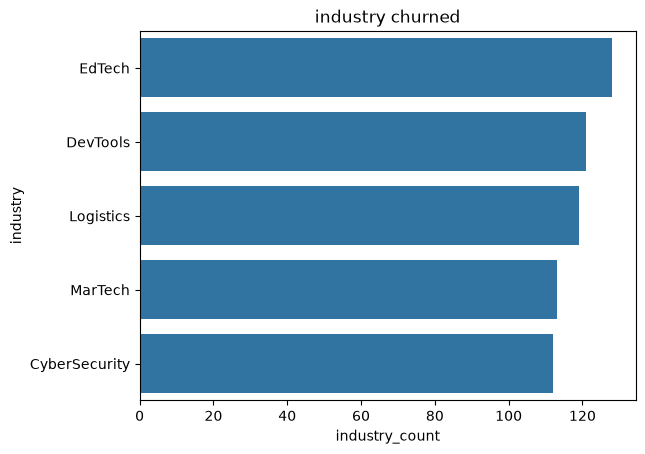

In [28]:
sns.barplot(data = industry_count,y = "industry",x ="industry_count")
plt.title("industry churned")
plt.xlabel("industry_count")
plt.ylabel("industry")
plt.show

In [29]:
plan_tier = churned_data.groupby("plan_tier").agg(plan_tier_count =("plan_tier","count")).sort_values(by ="plan_tier_count",ascending = False).reset_index()
plan_tier

,plan_tier,plan_tier_count
0,Starter,685
1,Pro,174
2,Enterprise,57


<function matplotlib.pyplot.show(close=None, block=None)>

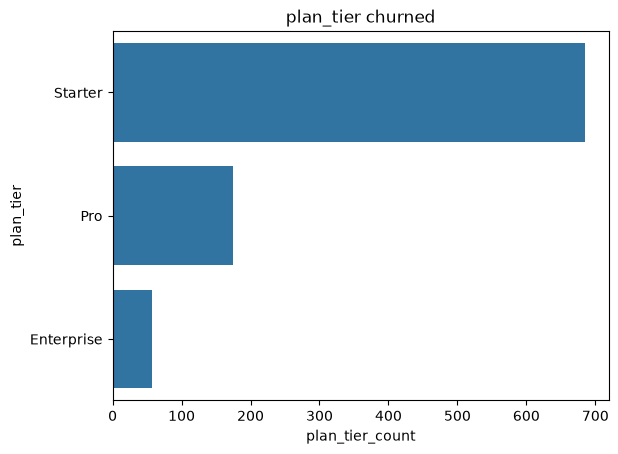

In [30]:
sns.barplot(data = plan_tier,y = "plan_tier",x ="plan_tier_count")
plt.title("plan_tier churned")
plt.xlabel("plan_tier_count")
plt.ylabel("plan_tier")
plt.show

In [31]:
payment_status = churned_data.groupby("payment_status").agg(plan_tier_count =("payment_status","count")).reset_index()
payment_status

,payment_status,plan_tier_count
0,Active,513
1,Failed,294
2,Pending,109


<function matplotlib.pyplot.show(close=None, block=None)>

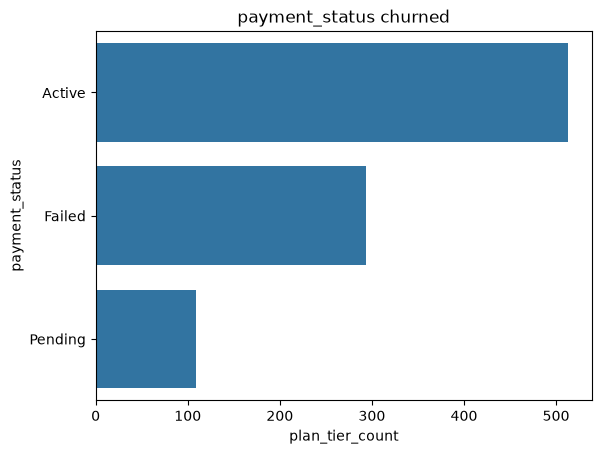

In [32]:
sns.barplot(data = payment_status,y = "payment_status",x ="plan_tier_count")
plt.title("payment_status churned")
plt.xlabel("plan_tier_count")
plt.ylabel("payment_status")
plt.show

In [33]:
count_country = churned_data.groupby("country").agg(country_count =("country","count")).sort_values(by = "country_count",ascending=False).reset_index().head(5)
count_country

,country,country_count
0,Singapore,135
1,USA,126
2,France,125
3,Germany,115
4,India,112


<function matplotlib.pyplot.show(close=None, block=None)>

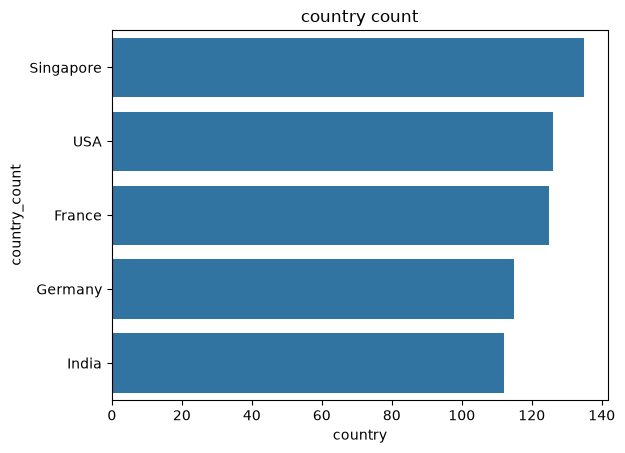

In [34]:
sns.barplot(data = count_country,y = "country",x ="country_count")
plt.title("country count")
plt.xlabel("country")
plt.ylabel("country_count")
plt.show

In [35]:
manager = churned_data.groupby("account_manager").agg(manager_count =("account_manager","count")).sort_values(by ="manager_count",ascending =False).reset_index()
manager

,account_manager,manager_count
0,Sarah Jenkins,195
1,Marcus Vance,195
2,Elena Rostova,186
3,David Ross,178
4,Aisha Khan,162


<function matplotlib.pyplot.show(close=None, block=None)>

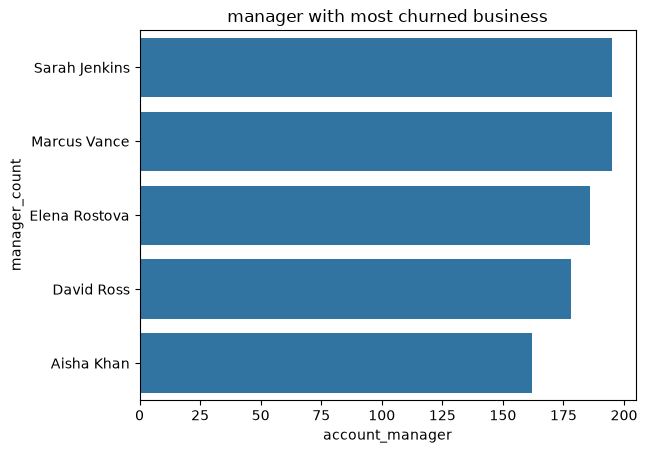

In [36]:
sns.barplot(data = manager,y = "account_manager",x ="manager_count")
plt.title("manager with most churned business")
plt.xlabel("account_manager")
plt.ylabel("manager_count")
plt.show

In [37]:
month = churned_data["last_active_date"].dt.month_name()

In [38]:
month

116       November
131       November
197        October
201        January
211        January
           ...    
49505      January
49645      October
49737    September
49779     December
49857      January
Name: last_active_date, Length: 916, dtype: str

In [44]:
churned_data['year'] = churned_data["last_active_date"].dt.year

In [45]:
churned_data['year']

116      2025
131      2025
197      2025
201      2026
211      2026
         ... 
49505    2026
49645    2025
49737    2025
49779    2025
49857    2026
Name: year, Length: 916, dtype: int32

In [41]:
print(churned_data)

      customer_id       company_name    industry    country company_size  \
116     CUST-1117   Quantum Tech 557      EdTech      India        11-50   
131     CUST-1132  Cloud Metrics 275     MarTech    Germany         1-10   
197     CUST-1198      Data Tech 683  E-Commerce        USA       51-200   
201     CUST-1202     Vibe Scale 531    DevTools  Australia      201-500   
211     CUST-1212     Nexus Labs 264     MarTech    Germany      201-500   
...           ...                ...         ...        ...          ...   
49505  CUST-50506  Nexus Metrics 457   Logistics     Canada         1-10   
49645  CUST-50646    Vibe Sphere 448     MarTech     France       51-200   
49737  CUST-50738     Pulse Flow 956    DevTools    Germany         1-10   
49779  CUST-50780       Vibe Net 599  HealthTech         UK         1-10   
49857  CUST-50858      Data Flow 932   Logistics    Germany         1-10   

      account_manager plan_tier billing_cycle  monthly_recurring_revenue  \
116        

In [47]:
count_year = churned_data.groupby("year").agg(Year__count =("year","count"))
count_year

,Year__count
year,
2025,742
2026,174
